<a href="https://colab.research.google.com/github/Infinity-rudra/Network-Anomaly-Detection-Isolation-Forest/blob/main/Cloud_Anomaly_Detection_Isolation_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.ensemble import IsolationForest

# Evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Utilities
import os
import warnings
import time

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
DATASET_PATH = "/content/drive/MyDrive/Research/CSE-CIC-IDS2018"

FILE_1 = os.path.join(
    DATASET_PATH,
    "Friday-16-02-2018_TrafficForML_CICFlowMeter.csv"
)

FILE_2 = os.path.join(
    DATASET_PATH,
    "Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv"
)

print("Dataset 1 exists:", os.path.exists(FILE_1))
print("Dataset 2 exists:", os.path.exists(FILE_2))

Dataset 1 exists: True
Dataset 2 exists: True


In [4]:
files = [FILE_1, FILE_2]

for file_path in files:

    print("\n" + "="*70)
    print("FILE:", os.path.basename(file_path))
    print("="*70)

    sample = pd.read_csv(file_path, nrows=5)

    print("\nNumber of columns:", len(sample.columns))

    print("\nColumn names:")
    print(sample.columns.tolist())

    print("\nFirst five records:")
    display(sample.head())


FILE: Friday-16-02-2018_TrafficForML_CICFlowMeter.csv

Number of columns: 80

Column names:
['Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Down/Up Ratio', 'Pkt Size Avg', 'Fwd Seg S

,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,0,0,16/02/2018 08:27:23,112640768,3,0,0,0,0,0,...,0,0,0,0,0,56300000,138.592929,56300000,56300000,Benign
1,0,0,16/02/2018 08:30:12,112641773,3,0,0,0,0,0,...,0,0,0,0,0,56300000,263.750829,56300000,56300000,Benign
2,35605,6,16/02/2018 08:26:55,20784143,23,44,2416,1344,240,64,...,20,2624734,0,2624734,2624734,9058214,0.000000,9058214,9058214,Benign
3,0,0,16/02/2018 08:33:01,112640836,3,0,0,0,0,0,...,0,0,0,0,0,56300000,82.024387,56300000,56300000,Benign
4,23,6,16/02/2018 08:27:59,20,1,1,0,0,0,0,...,20,0,0,0,0,0,0.000000,0,0,Benign



FILE: Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv

Number of columns: 80

Column names:
['Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Down/Up Ratio', 'Pkt Size Avg', 'Fwd Se

,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,6,21/02/2018 08:33:25,37953,5,3,135,127,135,0,...,32,0,0,0,0,0,0,0,0,Benign
1,500,17,21/02/2018 08:33:06,117573474,3,0,1500,0,500,500,...,8,0,0,0,0,58800000,23800000,75600000,42000000,Benign
2,500,17,21/02/2018 08:33:06,117573474,3,0,1500,0,500,500,...,8,0,0,0,0,58800000,23800000,75600000,42000000,Benign
3,500,17,21/02/2018 08:33:11,99743998,5,0,2500,0,500,500,...,8,4000290,0,4000290,4000290,31900000,37900000,75600000,7200397,Benign
4,500,17,21/02/2018 08:33:11,99743999,5,0,2500,0,500,500,...,8,4000286,0,4000286,4000286,31900000,37900000,75600000,7200399,Benign


In [5]:
for file_path in files:

    size_mb = os.path.getsize(file_path) / (1024 * 1024)

    print(
        os.path.basename(file_path),
        ":", round(size_mb, 2), "MB"
    )

Friday-16-02-2018_TrafficForML_CICFlowMeter.csv : 3.0 MB
Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv : 2.0 MB


In [6]:
for file_path in files:

    print("\nDataset:", os.path.basename(file_path))

    sample = pd.read_csv(file_path, nrows=5)

    label_columns = [
        col for col in sample.columns
        if "label" in col.lower()
    ]

    print("Possible label columns:", label_columns)


Dataset: Friday-16-02-2018_TrafficForML_CICFlowMeter.csv
Possible label columns: ['Label']

Dataset: Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv
Possible label columns: ['Label']


In [7]:
import pandas as pd
import os

files = {
    "Friday_16_Feb": FILE_1,
    "Wednesday_21_Feb": FILE_2
}

CHUNK_SIZE = 100_000

dataset_summary = {}

for dataset_name, file_path in files.items():

    print(f"\nProcessing: {dataset_name}")

    label_counts = {}
    total_records = 0

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE
    ):

        # Clean column names
        chunk.columns = chunk.columns.str.strip()

        # Clean labels
        labels = chunk["Label"].astype(str).str.strip()

        counts = labels.value_counts()

        for label, count in counts.items():

            label_counts[label] = (
                label_counts.get(label, 0) + count
            )

        total_records += len(chunk)

    dataset_summary[dataset_name] = {
        "Total Records": total_records,
        **label_counts
    }

    print("Total records:", total_records)
    print("Label distribution:")

    for label, count in label_counts.items():

        percentage = (count / total_records) * 100

        print(
            f"{label}: {count:,} "
            f"({percentage:.2f}%)"
        )


Processing: Friday_16_Feb
Total records: 13534
Label distribution:
DoS attacks-SlowHTTPTest: 13,429 (99.22%)
Benign: 104 (0.77%)
DoS atta: 1 (0.01%)

Processing: Wednesday_21_Feb
Total records: 6110
Label distribution:
Benign: 2,200 (36.01%)
DDOS attack-HOIC: 2,179 (35.66%)
DDOS attack-LOIC-UDP: 1,730 (28.31%)
nan: 1 (0.02%)


In [8]:
summary_df = pd.DataFrame(dataset_summary).fillna(0).T

display(summary_df)

,Total Records,DoS attacks-SlowHTTPTest,Benign,DoS atta,DDOS attack-HOIC,DDOS attack-LOIC-UDP,nan
Friday_16_Feb,13534.0,13429.0,104.0,1.0,0.0,0.0,0.0
Wednesday_21_Feb,6110.0,0.0,2200.0,0.0,2179.0,1730.0,1.0


In [9]:
import numpy as np

for dataset_name, file_path in files.items():

    print("\nDataset:", dataset_name)

    missing_counts = {}
    infinite_counts = {}
    total_records = 0

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE
    ):

        chunk.columns = chunk.columns.str.strip()

        total_records += len(chunk)

        missing = chunk.isnull().sum()

        for col, count in missing.items():
            missing_counts[col] = (
                missing_counts.get(col, 0) + count
            )

        numeric = chunk.select_dtypes(
            include=np.number
        )

        infinite = np.isinf(numeric).sum()

        for col, count in infinite.items():
            infinite_counts[col] = (
                infinite_counts.get(col, 0) + count
            )

    print("Total records:", total_records)

    print("\nColumns with missing values:")

    print({
        col: count
        for col, count in missing_counts.items()
        if count > 0
    })

    print("\nColumns with infinite values:")

    print({
        col: count
        for col, count in infinite_counts.items()
        if count > 0
    })


Dataset: Friday_16_Feb
Total records: 13534

Columns with missing values:
{}

Columns with infinite values:
{}

Dataset: Wednesday_21_Feb
Total records: 6110

Columns with missing values:
{'Flow Duration': 1, 'Tot Fwd Pkts': 1, 'Tot Bwd Pkts': 1, 'TotLen Fwd Pkts': 1, 'TotLen Bwd Pkts': 1, 'Fwd Pkt Len Max': 1, 'Fwd Pkt Len Min': 1, 'Fwd Pkt Len Mean': 1, 'Fwd Pkt Len Std': 1, 'Bwd Pkt Len Max': 1, 'Bwd Pkt Len Min': 1, 'Bwd Pkt Len Mean': 1, 'Bwd Pkt Len Std': 1, 'Flow Byts/s': 1, 'Flow Pkts/s': 1, 'Flow IAT Mean': 1, 'Flow IAT Std': 1, 'Flow IAT Max': 1, 'Flow IAT Min': 1, 'Fwd IAT Tot': 1, 'Fwd IAT Mean': 1, 'Fwd IAT Std': 1, 'Fwd IAT Max': 1, 'Fwd IAT Min': 1, 'Bwd IAT Tot': 1, 'Bwd IAT Mean': 1, 'Bwd IAT Std': 1, 'Bwd IAT Max': 1, 'Bwd IAT Min': 1, 'Fwd PSH Flags': 1, 'Bwd PSH Flags': 1, 'Fwd URG Flags': 1, 'Bwd URG Flags': 1, 'Fwd Header Len': 1, 'Bwd Header Len': 1, 'Fwd Pkts/s': 1, 'Bwd Pkts/s': 1, 'Pkt Len Min': 1, 'Pkt Len Max': 1, 'Pkt Len Mean': 1, 'Pkt Len Std': 1, 'Pkt L

In [10]:
import pandas as pd
import os

for file_path in [FILE_1, FILE_2]:

    print("\n" + "="*80)
    print("FILE:", os.path.basename(file_path))
    print("="*80)

    df = pd.read_csv(file_path)

    df.columns = df.columns.str.strip()

    # Display all unique labels
    print("\nUnique labels:")

    for label in df["Label"].unique():
        print(repr(label))

    # Identify missing labels
    missing_label = df[df["Label"].isna()]

    print("\nRecords with missing labels:")
    display(missing_label)

    # Identify suspicious or unexpected labels
    suspicious = df[
        df["Label"].astype(str).str.strip().str.lower()
        .str.startswith("dos atta")
        &
        (df["Label"].astype(str).str.strip() != "DoS attacks-SlowHTTPTest")
    ]

    print("\nSuspicious labels:")
    display(suspicious)


FILE: Friday-16-02-2018_TrafficForML_CICFlowMeter.csv

Unique labels:
'Benign'
'DoS attacks-SlowHTTPTest'
'DoS atta'

Records with missing labels:


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label



Suspicious labels:


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
13533,21,6,16/02/2018 10:18:58,2,1,1,0,0,0,0,...,40,0,0.0,0,0,0.0,0.0,0,0,DoS atta



FILE: Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv

Unique labels:
'Benign'
'DDOS attack-LOIC-UDP'
'DDOS attack-HOIC'
nan

Records with missing labels:


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
6109,80,6,21/02/20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Suspicious labels:


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label


In [11]:
for file_path in [FILE_1, FILE_2]:

    df = pd.read_csv(file_path)

    print("\nFile:", os.path.basename(file_path))

    print("Shape:", df.shape)

    print("\nData types:")

    print(df.dtypes.value_counts())

    print("\nDuplicate records:", df.duplicated().sum())


File: Friday-16-02-2018_TrafficForML_CICFlowMeter.csv
Shape: (13534, 80)

Data types:
int64      55
float64    23
object      2
Name: count, dtype: int64

Duplicate records: 10564

File: Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv
Shape: (6110, 80)

Data types:
float64    76
int64       2
object      2
Name: count, dtype: int64

Duplicate records: 21


In [12]:
import pandas as pd
import os

for file_path in [FILE_1, FILE_2]:

    print("\n" + "="*70)
    print("FILE:", os.path.basename(file_path))
    print("="*70)

    df = pd.read_csv(file_path)

    df.columns = df.columns.str.strip()

    df["Label"] = df["Label"].astype("string").str.strip()

    print("\nTotal records:", len(df))

    print("\nDuplicate records by label:")

    duplicate_mask = df.duplicated(keep="first")

    duplicate_analysis = pd.DataFrame({
        "Label": df["Label"],
        "Is_Duplicate": duplicate_mask
    })

    print(
        duplicate_analysis.groupby("Label", dropna=False)
        .agg(
            Total_Records=("Is_Duplicate", "size"),
            Duplicate_Records=("Is_Duplicate", "sum")
        )
    )

    print("\nNumber of unique records:", len(df.drop_duplicates()))

    print("\nExact duplicate examples:")

    display(df[duplicate_mask].head(5))


FILE: Friday-16-02-2018_TrafficForML_CICFlowMeter.csv

Total records: 13534

Duplicate records by label:
                          Total_Records  Duplicate_Records
Label                                                     
Benign                              104                  0
DoS atta                              1                  0
DoS attacks-SlowHTTPTest          13429              10564

Number of unique records: 2970

Exact duplicate examples:


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
99,21,6,16/02/2018 10:12:14,3,1,1,0,0,0,0,...,40,0,0.0,0,0,0.0,0.0,0,0,DoS attacks-SlowHTTPTest
100,21,6,16/02/2018 10:12:14,3,1,1,0,0,0,0,...,40,0,0.0,0,0,0.0,0.0,0,0,DoS attacks-SlowHTTPTest
102,21,6,16/02/2018 10:12:14,2,1,1,0,0,0,0,...,40,0,0.0,0,0,0.0,0.0,0,0,DoS attacks-SlowHTTPTest
103,21,6,16/02/2018 10:12:14,3,1,1,0,0,0,0,...,40,0,0.0,0,0,0.0,0.0,0,0,DoS attacks-SlowHTTPTest
104,21,6,16/02/2018 10:12:14,3,1,1,0,0,0,0,...,40,0,0.0,0,0,0.0,0.0,0,0,DoS attacks-SlowHTTPTest



FILE: Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv

Total records: 6110

Duplicate records by label:
                      Total_Records  Duplicate_Records
Label                                                 
Benign                         2200                  5
DDOS attack-HOIC               2179                 16
DDOS attack-LOIC-UDP           1730                  0
<NA>                              1                  0

Number of unique records: 6089

Exact duplicate examples:


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
2,500,17,21/02/2018 08:33:06,117573474.0,3.0,0.0,1500.0,0.0,500.0,500.0,...,8.0,0.0,0.0,0.0,0.0,58800000.0,23800000.0,75600000.0,42000000.0,Benign
11,500,17,21/02/2018 08:35:08,85479836.0,5.0,0.0,2500.0,0.0,500.0,500.0,...,8.0,0.0,0.0,0.0,0.0,21400000.0,15300000.0,42000000.0,7200407.0,Benign
145,500,17,21/02/2018 09:21:12,89479778.0,6.0,0.0,3000.0,0.0,500.0,500.0,...,8.0,4000329.0,0.0,4000329.0,4000329.0,21400000.0,15300000.0,42000000.0,7200325.0,Benign
160,500,17,21/02/2018 09:26:43,89479830.0,6.0,0.0,3000.0,0.0,500.0,500.0,...,8.0,4000331.0,0.0,4000331.0,4000331.0,21400000.0,15300000.0,42000000.0,7200346.0,Benign
3773,8080,6,21/02/2018 08:45:20,19.0,1.0,1.0,0.0,0.0,0.0,0.0,...,40.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign


In [13]:
for file_path in [FILE_1, FILE_2]:

    print("\nFILE:", os.path.basename(file_path))

    df = pd.read_csv(file_path)

    df.columns = df.columns.str.strip()

    print("\nUnique labels:")

    for label in df["Label"].drop_duplicates():
        print(repr(label))

    # Find labels beginning with DoS atta
    suspicious = df[
        df["Label"].astype(str).str.strip().str.startswith("DoS atta")
        &
        (df["Label"].astype(str).str.strip() !=
         "DoS attacks-SlowHTTPTest")
    ]

    print("\nSuspicious records:")
    display(suspicious)

    # Find records with missing labels
    missing = df[df["Label"].isna()]

    print("\nRecords with missing labels:")
    display(missing)


FILE: Friday-16-02-2018_TrafficForML_CICFlowMeter.csv

Unique labels:
'Benign'
'DoS attacks-SlowHTTPTest'
'DoS atta'

Suspicious records:


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
13533,21,6,16/02/2018 10:18:58,2,1,1,0,0,0,0,...,40,0,0.0,0,0,0.0,0.0,0,0,DoS atta



Records with missing labels:


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label



FILE: Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv

Unique labels:
'Benign'
'DDOS attack-LOIC-UDP'
'DDOS attack-HOIC'
nan

Suspicious records:


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label



Records with missing labels:


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
6109,80,6,21/02/20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
import pandas as pd
import numpy as np
import os

df1 = pd.read_csv(FILE_1)
df2 = pd.read_csv(FILE_2)

df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# Combine datasets
df = pd.concat([df1, df2], ignore_index=True)

# Clean label whitespace
df["Label"] = df["Label"].astype("string").str.strip()

print("Combined dataset shape:", df.shape)

print("\nLabel distribution:")
print(df["Label"].value_counts(dropna=False))

Combined dataset shape: (19644, 80)

Label distribution:
Label
DoS attacks-SlowHTTPTest    13429
Benign                       2304
DDOS attack-HOIC             2179
DDOS attack-LOIC-UDP         1730
DoS atta                        1
<NA>                            1
Name: count, dtype: Int64


In [15]:
# Remove missing labels
df = df.dropna(subset=["Label"]).copy()

# Keep only recognised labels for the primary experiment
valid_labels = [
    "Benign",
    "DoS attacks-SlowHTTPTest",
    "DDOS attack-HOIC",
    "DDOS attack-LOIC-UDP"
]

df = df[df["Label"].isin(valid_labels)].copy()

print("Shape after label cleaning:", df.shape)

print("\nUpdated label distribution:")
print(df["Label"].value_counts())

Shape after label cleaning: (19642, 80)

Updated label distribution:
Label
DoS attacks-SlowHTTPTest    13429
Benign                       2304
DDOS attack-HOIC             2179
DDOS attack-LOIC-UDP         1730
Name: count, dtype: Int64


In [16]:
# Original cleaned dataset
df_original = df.copy()

# Remove exact duplicate rows
df_deduplicated = df.drop_duplicates().copy()

print("Original cleaned records:", len(df_original))
print("Deduplicated records:", len(df_deduplicated))

print("\nOriginal distribution:")
print(df_original["Label"].value_counts())

print("\nDeduplicated distribution:")
print(df_deduplicated["Label"].value_counts())

Original cleaned records: 19642
Deduplicated records: 9057

Original distribution:
Label
DoS attacks-SlowHTTPTest    13429
Benign                       2304
DDOS attack-HOIC             2179
DDOS attack-LOIC-UDP         1730
Name: count, dtype: Int64

Deduplicated distribution:
Label
DoS attacks-SlowHTTPTest    2865
Benign                      2299
DDOS attack-HOIC            2163
DDOS attack-LOIC-UDP        1730
Name: count, dtype: Int64


In [17]:
# Select the deduplicated dataset
model_df = df_deduplicated.copy()

# Separate labels
y = model_df["Label"].copy()

# Remove target and timestamp
X = model_df.drop(
    columns=["Label", "Timestamp"],
    errors="ignore"
)

# Convert all features to numeric where possible
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Identify invalid columns
invalid_columns = X.columns[X.isna().any()].tolist()

print("Total features:", X.shape[1])
print("Features with missing values:", invalid_columns)

print("\nFeature matrix shape:", X.shape)

Total features: 78
Features with missing values: []

Feature matrix shape: (9057, 78)


In [18]:
# CELL 18: Feature inspection

print("Feature matrix shape:", model_df.shape)

# Check data types
print("\nData types:")
print(model_df.dtypes.value_counts())

# Check constant features
constant_features = [
    col for col in model_df.columns
    if model_df[col].nunique(dropna=False) <= 1
]

print("\nConstant features:", constant_features)
print("Number of constant features:", len(constant_features))

# Check duplicate feature rows, excluding labels
# Timestamp has already been removed from the feature matrix.
feature_duplicates = model_df.duplicated(
    subset=[col for col in model_df.columns if col != "Label"]
).sum()

print("\nDuplicate feature rows:", feature_duplicates)

# Check feature ranges
print("\nFeature summary:")
display(model_df.drop(columns=["Label"]).describe().T)

# Inspect Protocol values if the column exists
if "Protocol" in model_df.columns:
    print("\nProtocol value counts:")
    print(model_df["Protocol"].value_counts(dropna=False))

Feature matrix shape: (9057, 80)

Data types:
float64           76
int64              2
object             1
string[python]     1
Name: count, dtype: int64

Constant features: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg']
Number of constant features: 10

Duplicate feature rows: 0

Feature summary:


,count,mean,std,min,25%,50%,75%,max
Dst Port,9057.0,3.663779e+02,3.421667e+03,0.0,21.0,80.0,80.0,60477.0
Protocol,9057.0,1.031059e+01,5.468866e+00,0.0,6.0,6.0,17.0,17.0
Flow Duration,9057.0,4.512543e+07,5.543799e+07,1.0,21.0,27927.0,114995836.0,119999998.0
Tot Fwd Pkts,9057.0,2.241912e+04,4.775765e+04,1.0,1.0,3.0,14.0,309629.0
Tot Bwd Pkts,9057.0,1.053550e+00,9.691128e+00,0.0,0.0,0.0,1.0,889.0
...,...,...,...,...,...,...,...,...
Active Min,9057.0,6.092856e+05,1.546383e+06,0.0,0.0,0.0,0.0,20000000.0
Idle Mean,9057.0,3.724842e+06,8.792640e+06,0.0,0.0,0.0,0.0,106000000.0
Idle Std,9057.0,1.767121e+06,4.164035e+06,0.0,0.0,0.0,0.0,50300000.0
Idle Max,9057.0,6.597442e+06,1.386006e+07,0.0,0.0,0.0,0.0,106000000.0



Protocol value counts:
Protocol
6     5361
17    3601
0       95
Name: count, dtype: int64


In [19]:
# CELL 19: Verify columns and data types

print("Total columns:", len(model_df.columns))

print("\nAll columns:")
print(model_df.columns.tolist())

print("\nNon-numeric columns:")
print(
    model_df.select_dtypes(exclude=["number"]).columns.tolist()
)

print("\nLabel column present:", "Label" in model_df.columns)
print("Timestamp column present:", "Timestamp" in model_df.columns)

if "Label" in model_df.columns:
    print("\nLabel distribution:")
    print(model_df["Label"].value_counts(dropna=False))

Total columns: 80

All columns:
['Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Down/Up Ratio', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg', 'Fwd Byts/b Avg', 'Fwd Pkts/b A

In [20]:
# CELL 20: Final feature preparation

import numpy as np
import pandas as pd

# Separate target labels
y = model_df["Label"].copy()

# Remove Label and Timestamp from input features
X = model_df.drop(columns=["Label", "Timestamp"]).copy()

# Remove constant features
constant_features = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

X = X.drop(columns=constant_features)

# Convert Protocol into categorical dummy variables
X["Protocol"] = X["Protocol"].astype(str)

X = pd.get_dummies(
    X,
    columns=["Protocol"],
    prefix="Protocol",
    dtype=int
)

# Ensure all features are numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

print("Removed constant features:", len(constant_features))
print("Constant features:", constant_features)

print("\nFinal feature matrix shape:", X.shape)
print("Remaining missing values:", X.isna().sum().sum())
print("\nFinal feature columns:")
print(X.columns.tolist())

print("\nLabel distribution:")
print(y.value_counts())

Removed constant features: 10
Constant features: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg']

Final feature matrix shape: (9057, 70)
Remaining missing values: 0

Final feature columns:
['Dst Port', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SY

In [21]:
# CELL 21: Train, validation and test split

from sklearn.model_selection import train_test_split
import pandas as pd

# Identify benign and attack records
benign_indices = y[y == "Benign"].index
attack_indices = y[y != "Benign"].index

# Split benign records: 60% training, 40% remaining
train_indices, remaining_indices = train_test_split(
    benign_indices,
    test_size=0.40,
    random_state=42
)

# Divide remaining benign records equally:
# 20% validation and 20% testing
val_indices, benign_test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    random_state=42
)

# Training data: benign only
X_train = X.loc[train_indices].copy()

# Validation data: benign only
X_val = X.loc[val_indices].copy()

# Final test data: benign test + all attacks
X_test = pd.concat([
    X.loc[benign_test_indices],
    X.loc[attack_indices]
])

# Actual labels for final evaluation
y_test = pd.Series(
    0,
    index=X_test.index,
    name="Actual"
)

y_test.loc[attack_indices] = 1

# Display dataset sizes
print("TRAINING SET")
print("Records:", len(X_train))
print("Classes:", y.loc[X_train.index].value_counts().to_dict())

print("\nVALIDATION SET")
print("Records:", len(X_val))
print("Classes:", y.loc[X_val.index].value_counts().to_dict())

print("\nFINAL TEST SET")
print("Total records:", len(X_test))
print("Benign records:", (y_test == 0).sum())
print("Attack records:", (y_test == 1).sum())

print("\nAttack distribution in final test set:")
print(y.loc[attack_indices].value_counts())

# Verify no attack records entered training or validation
assert (y.loc[X_train.index] == "Benign").all()
assert (y.loc[X_val.index] == "Benign").all()

print("\nVerification successful: Training and validation contain only benign traffic.")

TRAINING SET
Records: 1379
Classes: {'Benign': 1379}

VALIDATION SET
Records: 460
Classes: {'Benign': 460}

FINAL TEST SET
Total records: 7218
Benign records: 460
Attack records: 6758

Attack distribution in final test set:
Label
DoS attacks-SlowHTTPTest    2865
DDOS attack-HOIC            2163
DDOS attack-LOIC-UDP        1730
Name: count, dtype: Int64

Verification successful: Training and validation contain only benign traffic.


In [22]:
# CELL 22: Train Isolation Forest

from sklearn.ensemble import IsolationForest
import time

# Initialize model
iso_model = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# Train using benign traffic ONLY
start_time = time.time()

iso_model.fit(X_train)

training_time = time.time() - start_time

print("Isolation Forest training completed!")
print(f"Training time: {training_time:.2f} seconds")
print("Training records:", len(X_train))
print("Features used:", X_train.shape[1])
print("Trees:", iso_model.n_estimators)

Isolation Forest training completed!
Training time: 1.48 seconds
Training records: 1379
Features used: 70
Trees: 200


In [23]:
# CELL 23: Calibrate anomaly threshold using benign validation data

import numpy as np

# Isolation Forest score_samples:
# Lower scores indicate more anomalous observations
val_scores = iso_model.score_samples(X_val)

# Target false positive rate on benign validation traffic
target_fpr = 0.05

# Calculate threshold
threshold = np.percentile(
    val_scores,
    target_fpr * 100
)

# Classify validation records
val_predictions = (val_scores < threshold).astype(int)

# Calculate actual validation false-positive rate
validation_fpr = val_predictions.mean()

print("THRESHOLD CALIBRATION")
print("-" * 40)

print(f"Target validation FPR: {target_fpr:.2%}")
print(f"Selected anomaly threshold: {threshold:.6f}")
print(f"Actual validation FPR: {validation_fpr:.2%}")

print("\nValidation score statistics:")
print(f"Minimum score: {val_scores.min():.6f}")
print(f"Maximum score: {val_scores.max():.6f}")
print(f"Mean score: {val_scores.mean():.6f}")
print(f"Median score: {np.median(val_scores):.6f}")

print("\nValidation observations classified as anomalies:")
print(val_predictions.sum(), "/", len(val_predictions))

THRESHOLD CALIBRATION
----------------------------------------
Target validation FPR: 5.00%
Selected anomaly threshold: -0.567216
Actual validation FPR: 5.00%

Validation score statistics:
Minimum score: -0.653769
Maximum score: -0.325496
Mean score: -0.390585
Median score: -0.354365

Validation observations classified as anomalies:
23 / 460


In [24]:
# CELL 24: Final model evaluation

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate anomaly scores on test data
test_scores = iso_model.score_samples(X_test)

# Apply the threshold established using validation data
y_pred = (test_scores < threshold).astype(int)

# Ground truth:
# 0 = Benign
# 1 = Attack
y_true = y_test.values

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

TN, FP, FN, TP = cm.ravel()

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

fpr = FP / (FP + TN) if (FP + TN) else 0
fnr = FN / (FN + TP) if (FN + TP) else 0

# ROC-AUC: lower Isolation Forest score means more anomalous,
# therefore negate the score for ROC-AUC calculation
roc_auc = roc_auc_score(y_true, -test_scores)

# Print results
print("=" * 55)
print("FINAL TEST RESULTS - ISOLATION FOREST")
print("=" * 55)

print("\nConfusion Matrix:")
print(cm)

print("\nConfusion Matrix Interpretation:")
print(f"True Negatives (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print(f"True Positives (TP): {TP}")

print("\nPerformance Metrics:")
print(f"Accuracy:          {accuracy:.4f} ({accuracy:.2%})")
print(f"Precision:         {precision:.4f} ({precision:.2%})")
print(f"Recall:            {recall:.4f} ({recall:.2%})")
print(f"F1-score:          {f1:.4f}")
print(f"False Positive Rate:{fpr:.4f} ({fpr:.2%})")
print(f"False Negative Rate:{fnr:.4f} ({fnr:.2%})")
print(f"ROC-AUC:           {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Benign", "Attack"],
    zero_division=0
))

FINAL TEST RESULTS - ISOLATION FOREST

Confusion Matrix:
[[ 443   17]
 [5664 1094]]

Confusion Matrix Interpretation:
True Negatives (TN): 443
False Positives (FP): 17
False Negatives (FN): 5664
True Positives (TP): 1094

Performance Metrics:
Accuracy:          0.2129 (21.29%)
Precision:         0.9847 (98.47%)
Recall:            0.1619 (16.19%)
F1-score:          0.2781
False Positive Rate:0.0370 (3.70%)
False Negative Rate:0.8381 (83.81%)
ROC-AUC:           0.9024

Classification Report:
              precision    recall  f1-score   support

      Benign       0.07      0.96      0.13       460
      Attack       0.98      0.16      0.28      6758

    accuracy                           0.21      7218
   macro avg       0.53      0.56      0.21      7218
weighted avg       0.93      0.21      0.27      7218



# Experiment 2: Threshold Optimization

## Objective
To investigate how different anomaly-detection thresholds
affect attack detection performance and false-positive rate.

## Method
The thresholds will be evaluated using the benign validation
dataset. The test dataset will not be used for threshold selection.

In [25]:
# EXPERIMENT 2 - CELL 25
# Generate candidate thresholds using benign validation scores

import numpy as np
import pandas as pd

# Reuse validation scores from Experiment 1
# Lower Isolation Forest scores = more anomalous

target_fprs = [0.01, 0.03, 0.05, 0.07, 0.10, 0.15, 0.20]

threshold_candidates = {}

for target in target_fprs:
    candidate_threshold = np.percentile(
        val_scores,
        target * 100
    )

    threshold_candidates[target] = candidate_threshold

print("Candidate thresholds generated successfully.\n")

for target, candidate in threshold_candidates.items():
    print(
        f"Target FPR: {target:.0%} "
        f"| Threshold: {candidate:.6f}"
    )

Candidate thresholds generated successfully.

Target FPR: 1% | Threshold: -0.618601
Target FPR: 3% | Threshold: -0.586267
Target FPR: 5% | Threshold: -0.567216
Target FPR: 7% | Threshold: -0.533062
Target FPR: 10% | Threshold: -0.500511
Target FPR: 15% | Threshold: -0.481320
Target FPR: 20% | Threshold: -0.437319


In [26]:
# EXPERIMENT 2 - CELL 26
# Evaluate candidate thresholds using benign validation data

threshold_results = []

for target_fpr, candidate_threshold in threshold_candidates.items():

    # Predict anomalies
    val_pred = (val_scores < candidate_threshold).astype(int)

    # Since validation contains only benign records:
    FP = val_pred.sum()
    TN = len(val_pred) - FP

    actual_fpr = FP / (FP + TN)

    threshold_results.append({
        "Target_FPR": target_fpr,
        "Threshold": candidate_threshold,
        "False_Alarms": int(FP),
        "Correctly_Normal": int(TN),
        "Actual_Validation_FPR": actual_fpr
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(6))

,Target_FPR,Threshold,False_Alarms,Correctly_Normal,Actual_Validation_FPR
0,0.01,-0.618601,5,455,0.010870
1,0.03,-0.586267,14,446,0.030435
2,0.05,-0.567216,23,437,0.050000
3,0.07,-0.533062,33,427,0.071739
4,0.10,-0.500511,46,414,0.100000
5,0.15,-0.481320,69,391,0.150000
6,0.20,-0.437319,92,368,0.200000


In [28]:
# EXPERIMENT 2 - FIX
# Convert test labels into binary labels

y_test_binary = (y_test != "Benign").astype(int)

print("Binary test labels created successfully.")
print("\nLabel distribution:")
print(pd.Series(y_test_binary).value_counts().rename({
    0: "Benign",
    1: "Attack"
}))

Binary test labels created successfully.

Label distribution:
Actual
Attack    7218
Name: count, dtype: int64


In [31]:
# EXPERIMENT 2 - CELL 27 (CORRECTED)
# Evaluate using the already binary-encoded test labels

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Use original binary test labels directly
y_test_binary = y_test.copy()

# Selected threshold from validation
selected_threshold = threshold_candidates[0.10]

# Predict anomalies
test_pred_exp2 = (test_scores < selected_threshold).astype(int)

# Confusion matrix
cm_exp2 = confusion_matrix(y_test_binary, test_pred_exp2)

TN, FP, FN, TP = cm_exp2.ravel()

# Calculate metrics
accuracy_exp2 = accuracy_score(y_test_binary, test_pred_exp2)
precision_exp2 = precision_score(y_test_binary, test_pred_exp2, zero_division=0)
recall_exp2 = recall_score(y_test_binary, test_pred_exp2, zero_division=0)
f1_exp2 = f1_score(y_test_binary, test_pred_exp2, zero_division=0)

fpr_exp2 = FP / (FP + TN)
fnr_exp2 = FN / (FN + TP)

auc_exp2 = roc_auc_score(y_test_binary, -test_scores)

print("EXPERIMENT 2 - RESULTS")
print("=" * 50)

print(f"Selected Threshold: {selected_threshold:.6f}")
print("Target Validation FPR: 10%")
print(f"Actual Validation FPR: {threshold_df.loc[threshold_df['Target_FPR'] == 0.10, 'Actual_Validation_FPR'].values[0]:.2%}")

print("\nConfusion Matrix:")
print(cm_exp2)

print("\nMetrics:")
print(f"Accuracy:  {accuracy_exp2:.4f} ({accuracy_exp2:.2%})")
print(f"Precision: {precision_exp2:.4f} ({precision_exp2:.2%})")
print(f"Recall:    {recall_exp2:.4f} ({recall_exp2:.2%})")
print(f"F1-Score:  {f1_exp2:.4f}")
print(f"Test FPR:  {fpr_exp2:.4f} ({fpr_exp2:.2%})")
print(f"Test FNR:  {fnr_exp2:.4f} ({fnr_exp2:.2%})")
print(f"ROC-AUC:   {auc_exp2:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_binary,
    test_pred_exp2,
    target_names=["Benign", "Attack"],
    zero_division=0
))

EXPERIMENT 2 - RESULTS
Selected Threshold: -0.500511
Target Validation FPR: 10%
Actual Validation FPR: 10.00%

Confusion Matrix:
[[ 425   35]
 [3725 3033]]

Metrics:
Accuracy:  0.4791 (47.91%)
Precision: 0.9886 (98.86%)
Recall:    0.4488 (44.88%)
F1-Score:  0.6173
Test FPR:  0.0761 (7.61%)
Test FNR:  0.5512 (55.12%)
ROC-AUC:   0.9024

Classification Report:
              precision    recall  f1-score   support

      Benign       0.10      0.92      0.18       460
      Attack       0.99      0.45      0.62      6758

    accuracy                           0.48      7218
   macro avg       0.55      0.69      0.40      7218
weighted avg       0.93      0.48      0.59      7218



Experiment- 3 - Graph Analysis

In [32]:
# EXPERIMENT 3 - CELL 28
# Threshold Sensitivity Analysis

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

sensitivity_results = []

for target_fpr, threshold in threshold_candidates.items():

    # Predict attacks using the candidate threshold
    predictions = (test_scores < threshold).astype(int)

    # Calculate confusion matrix components
    TN, FP, FN, TP = confusion_matrix(
        y_test_binary, predictions
    ).ravel()

    # Calculate metrics
    accuracy = accuracy_score(y_test_binary, predictions)
    precision = precision_score(
        y_test_binary, predictions, zero_division=0
    )
    recall = recall_score(
        y_test_binary, predictions, zero_division=0
    )
    f1 = f1_score(
        y_test_binary, predictions, zero_division=0
    )

    test_fpr = FP / (FP + TN)
    test_fnr = FN / (FN + TP)

    sensitivity_results.append({
        "Target_Validation_FPR": target_fpr,
        "Threshold": threshold,
        "Test_TN": TN,
        "Test_FP": FP,
        "Test_FN": FN,
        "Test_TP": TP,
        "Test_FPR": test_fpr,
        "Test_FNR": test_fnr,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1
    })

# Convert results to DataFrame
sensitivity_df = pd.DataFrame(sensitivity_results)

print("EXPERIMENT 3 - THRESHOLD SENSITIVITY RESULTS")
print("=" * 80)

display(sensitivity_df.round(4))

EXPERIMENT 3 - THRESHOLD SENSITIVITY RESULTS


,Target_Validation_FPR,Threshold,Test_TN,Test_FP,Test_FN,Test_TP,Test_FPR,Test_FNR,Accuracy,Precision,Recall,F1_Score
0,0.01,-0.6186,455,5,6758,0,0.0109,1.0000,0.0630,0.0000,0.0000,0.0000
1,0.03,-0.5863,446,14,5664,1094,0.0304,0.8381,0.2134,0.9874,0.1619,0.2782
2,0.05,-0.5672,443,17,5664,1094,0.0370,0.8381,0.2129,0.9847,0.1619,0.2781
3,0.07,-0.5331,437,23,5664,1094,0.0500,0.8381,0.2121,0.9794,0.1619,0.2778
4,0.10,-0.5005,425,35,3725,3033,0.0761,0.5512,0.4791,0.9886,0.4488,0.6173
5,0.15,-0.4813,407,53,2212,4546,0.1152,0.3273,0.6862,0.9885,0.6727,0.8006
6,0.20,-0.4373,371,89,1042,5716,0.1935,0.1542,0.8433,0.9847,0.8458,0.9100


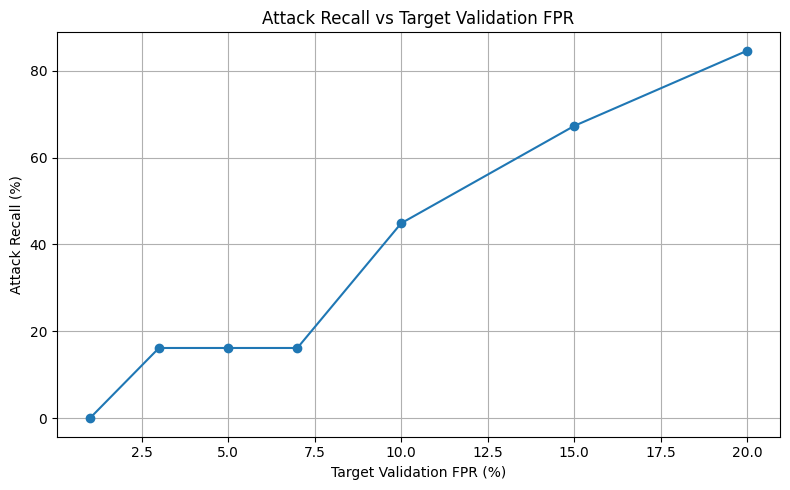

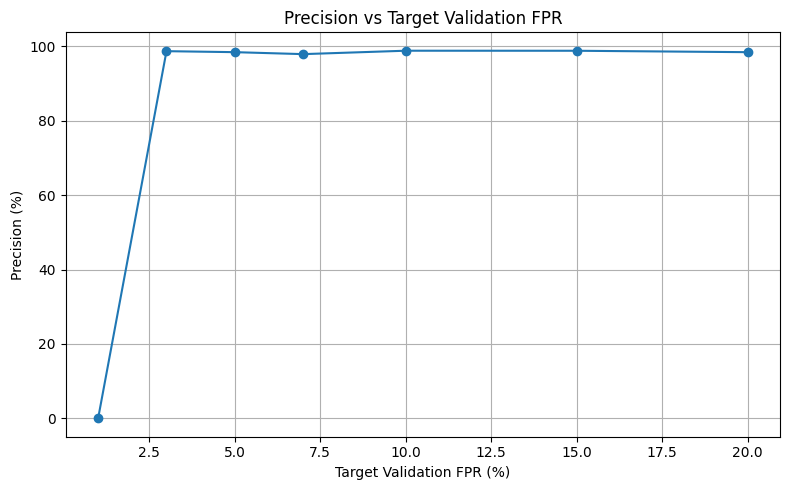

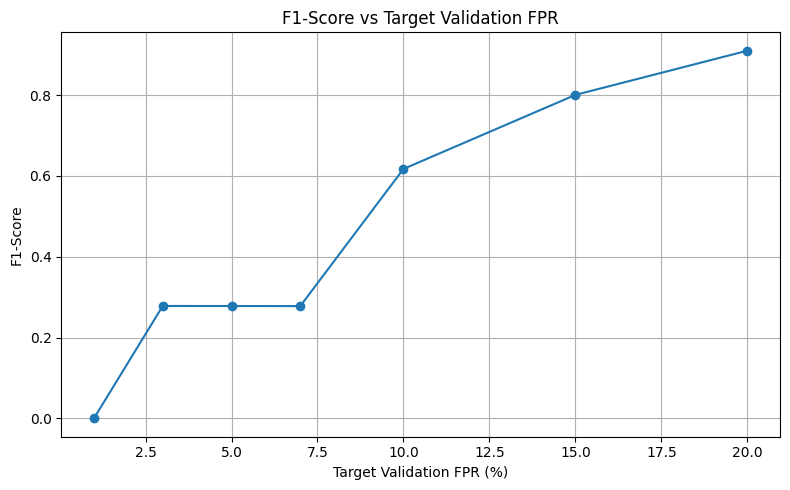

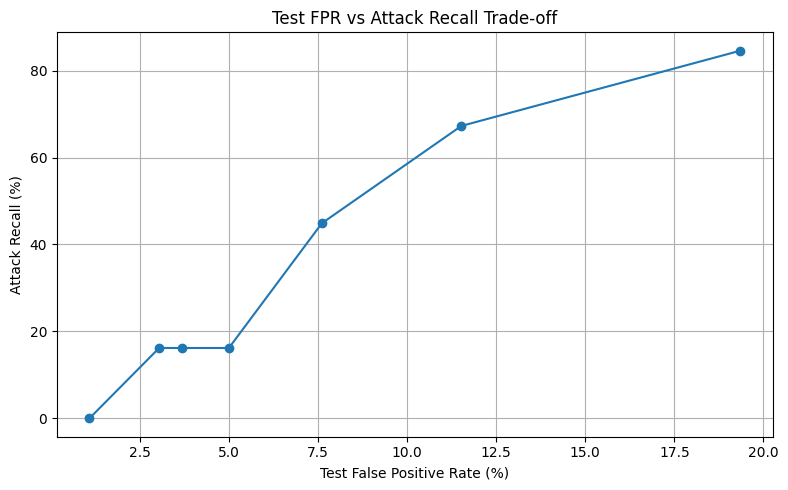

In [33]:
# EXPERIMENT 3 - CELL 29
# Visualization of Threshold Sensitivity

import matplotlib.pyplot as plt

# Convert target FPR to percentages
target_fpr_percent = sensitivity_df["Target_Validation_FPR"] * 100

# 1. Recall vs Target Validation FPR
plt.figure(figsize=(8, 5))
plt.plot(
    target_fpr_percent,
    sensitivity_df["Recall"] * 100,
    marker="o"
)
plt.xlabel("Target Validation FPR (%)")
plt.ylabel("Attack Recall (%)")
plt.title("Attack Recall vs Target Validation FPR")
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Precision vs Target Validation FPR
plt.figure(figsize=(8, 5))
plt.plot(
    target_fpr_percent,
    sensitivity_df["Precision"] * 100,
    marker="o"
)
plt.xlabel("Target Validation FPR (%)")
plt.ylabel("Precision (%)")
plt.title("Precision vs Target Validation FPR")
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. F1-score vs Target Validation FPR
plt.figure(figsize=(8, 5))
plt.plot(
    target_fpr_percent,
    sensitivity_df["F1_Score"],
    marker="o"
)
plt.xlabel("Target Validation FPR (%)")
plt.ylabel("F1-Score")
plt.title("F1-Score vs Target Validation FPR")
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Test FPR vs Attack Recall
plt.figure(figsize=(8, 5))
plt.plot(
    sensitivity_df["Test_FPR"] * 100,
    sensitivity_df["Recall"] * 100,
    marker="o"
)
plt.xlabel("Test False Positive Rate (%)")
plt.ylabel("Attack Recall (%)")
plt.title("Test FPR vs Attack Recall Trade-off")
plt.grid(True)
plt.tight_layout()
plt.show()

Experiment-4 - Attack-wise Detection Analysis

In [37]:
# EXPERIMENT 4 - CELL 30A
# Recover original multiclass labels for the existing test set

# Retrieve original attack labels using the test-set indices
y_test_labels = df_deduplicated.loc[y_test.index, "Label"]

# Align labels explicitly with X_test order
y_test_labels = y_test_labels.reindex(X_test.index)

# Verify alignment
assert len(y_test_labels) == len(X_test)
assert y_test_labels.index.equals(X_test.index)

# Verify binary labels correspond to the recovered multiclass labels
reconstructed_binary = (y_test_labels != "Benign").astype(int)

assert np.array_equal(
    reconstructed_binary.values,
    y_test.values
), "Mismatch between original and binary test labels!"

print("Original multiclass test labels recovered successfully.")
print("\nTest label distribution:")
print(y_test_labels.value_counts())

print("\nBinary-label consistency verified.")

Original multiclass test labels recovered successfully.

Test label distribution:
Label
DoS attacks-SlowHTTPTest    2865
DDOS attack-HOIC            2163
DDOS attack-LOIC-UDP        1730
Benign                       460
Name: count, dtype: Int64

Binary-label consistency verified.


In [38]:
# EXPERIMENT 4 - CELL 30B
# Attack-wise Detection Analysis

# Use the selected 10% validation-FPR threshold
selected_threshold = threshold_candidates[0.10]

# Create test results dataframe
attack_analysis = pd.DataFrame({
    "Actual_Label": y_test_labels.values,
    "Anomaly_Score": test_scores,
    "Prediction": test_pred_exp2
}, index=X_test.index)

# Select attack records only
attack_only = attack_analysis[
    attack_analysis["Actual_Label"] != "Benign"
].copy()

# Calculate performance for each attack category
attack_wise_results = []

for attack_name, group in attack_only.groupby("Actual_Label"):

    total_attacks = len(group)

    detected = (group["Prediction"] == 1).sum()

    missed = (group["Prediction"] == 0).sum()

    detection_rate = detected / total_attacks

    attack_wise_results.append({
        "Attack_Type": attack_name,
        "Total_Attacks": total_attacks,
        "Detected": detected,
        "Missed": missed,
        "Detection_Rate": detection_rate
    })

# Create results table
attack_wise_df = pd.DataFrame(attack_wise_results)

# Sort by detection rate, highest first
attack_wise_df = attack_wise_df.sort_values(
    "Detection_Rate",
    ascending=False
).reset_index(drop=True)

print("EXPERIMENT 4 - ATTACK-WISE DETECTION RESULTS")
print("=" * 70)

display(attack_wise_df.round(4))

EXPERIMENT 4 - ATTACK-WISE DETECTION RESULTS


,Attack_Type,Total_Attacks,Detected,Missed,Detection_Rate
0,DoS attacks-SlowHTTPTest,2865,1476,1389,0.5152
1,DDOS attack-HOIC,2163,1094,1069,0.5058
2,DDOS attack-LOIC-UDP,1730,463,1267,0.2676


Experiment-5 - ANOMALY SCORE DISTRIBUTION ANALYSIS

In [39]:
# EXPERIMENT 5 - ANOMALY SCORE DISTRIBUTION ANALYSIS

score_analysis = pd.DataFrame({
    "Actual_Label": y_test_labels.values,
    "Anomaly_Score": test_scores,
    "Prediction": test_pred_exp2
}, index=X_test.index)

print("Experiment 5 dataset created successfully.")
print("Total samples:", len(score_analysis))

print("\nSample distribution:")
print(score_analysis["Actual_Label"].value_counts())

Experiment 5 dataset created successfully.
Total samples: 7218

Sample distribution:
Actual_Label
DoS attacks-SlowHTTPTest    2865
DDOS attack-HOIC            2163
DDOS attack-LOIC-UDP        1730
Benign                       460
Name: count, dtype: Int64


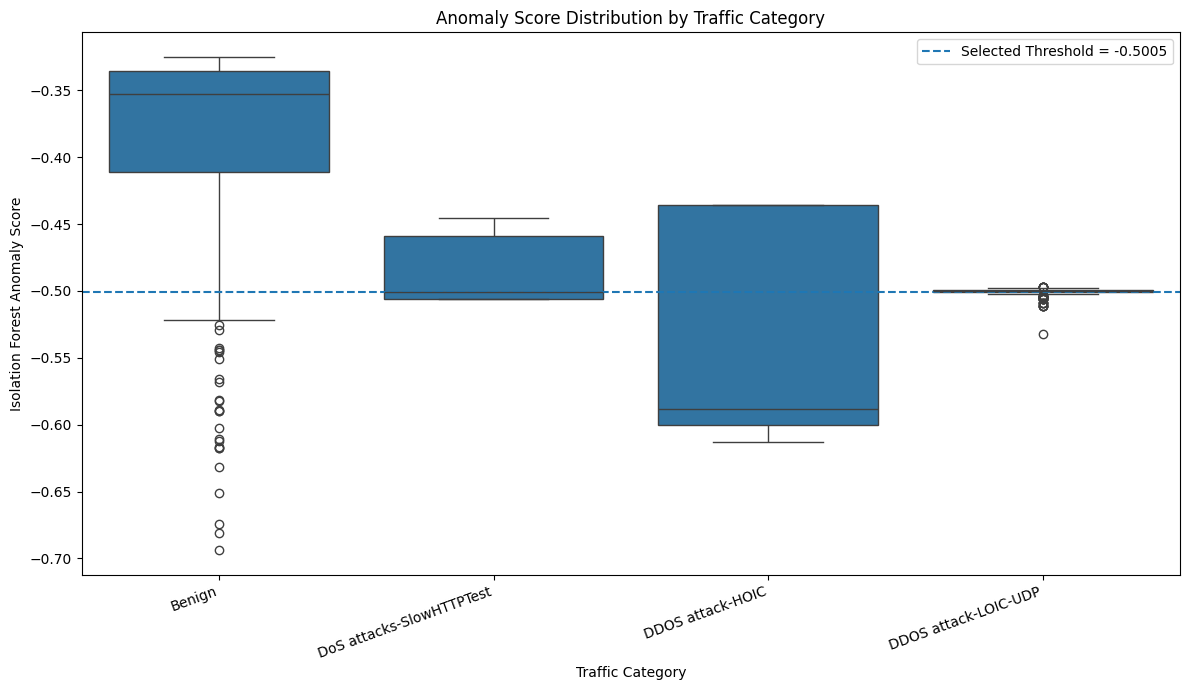

In [40]:
# EXPERIMENT 5 - ANOMALY SCORE BOXPLOT

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=score_analysis,
    x="Actual_Label",
    y="Anomaly_Score",
    order=[
        "Benign",
        "DoS attacks-SlowHTTPTest",
        "DDOS attack-HOIC",
        "DDOS attack-LOIC-UDP"
    ]
)

plt.axhline(
    selected_threshold,
    linestyle="--",
    label=f"Selected Threshold = {selected_threshold:.4f}"
)

plt.title("Anomaly Score Distribution by Traffic Category")
plt.xlabel("Traffic Category")
plt.ylabel("Isolation Forest Anomaly Score")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [41]:
# EXPERIMENT 5 - SCORE STATISTICS

score_statistics = (
    score_analysis
    .groupby("Actual_Label")["Anomaly_Score"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex([
        "Benign",
        "DoS attacks-SlowHTTPTest",
        "DDOS attack-HOIC",
        "DDOS attack-LOIC-UDP"
    ])
)

print("EXPERIMENT 5 - ANOMALY SCORE STATISTICS")
display(score_statistics.round(5))

EXPERIMENT 5 - ANOMALY SCORE STATISTICS


,count,mean,median,std,min,max
Actual_Label,,,,,,
Benign,460,-0.38592,-0.35251,0.07131,-0.69379,-0.32503
DoS attacks-SlowHTTPTest,2865,-0.48520,-0.50111,0.02236,-0.50622,-0.44552
DDOS attack-HOIC,2163,-0.51810,-0.58795,0.08121,-0.61266,-0.43574
DDOS attack-LOIC-UDP,1730,-0.50029,-0.50026,0.00133,-0.53242,-0.49722


EXPERIMENT 6 - FALSE POSITIVE & FALSE NEGATIVE ANALYSIS

In [42]:
# EXPERIMENT 6 - FALSE POSITIVE & FALSE NEGATIVE ANALYSIS

from sklearn.metrics import confusion_matrix

# Actual and predicted binary labels
actual = y_test.values
predicted = test_pred_exp2

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    actual,
    predicted,
    labels=[0, 1]
).ravel()

# Error summary
error_summary = pd.DataFrame({
    "Metric": [
        "True Negatives (TN)",
        "False Positives (FP)",
        "False Negatives (FN)",
        "True Positives (TP)",
        "Total Errors",
        "Total Test Samples"
    ],
    "Count": [
        tn,
        fp,
        fn,
        tp,
        fp + fn,
        len(actual)
    ]
})

print("EXPERIMENT 6 - ERROR ANALYSIS")
display(error_summary)

print("\nFalse Positive Rate:", round(fp / (fp + tn), 4))
print("False Negative Rate:", round(fn / (fn + tp), 4))

EXPERIMENT 6 - ERROR ANALYSIS


,Metric,Count
0,True Negatives (TN),425
1,False Positives (FP),35
2,False Negatives (FN),3725
3,True Positives (TP),3033
4,Total Errors,3760
5,Total Test Samples,7218



False Positive Rate: 0.0761
False Negative Rate: 0.5512


 EXPERIMENT 7 - FINAL PERFORMANCE COMPARISON

In [43]:
# EXPERIMENT 7 - FINAL PERFORMANCE COMPARISON

final_comparison = pd.DataFrame([
    {
        "Experiment": "Baseline (5% Threshold)",
        "Threshold": -0.567216,
        "Test_FPR": 0.0370,
        "Precision": 0.9847,
        "Recall": 0.1619,
        "F1_Score": 0.2781,
        "ROC_AUC": 0.9024
    },
    {
        "Experiment": "Selected Threshold (10%)",
        "Threshold": -0.500511,
        "Test_FPR": 0.0761,
        "Precision": 0.9886,
        "Recall": 0.4488,
        "F1_Score": 0.6173,
        "ROC_AUC": 0.9024
    },
    {
        "Experiment": "Threshold (15%)",
        "Threshold": -0.481320,
        "Test_FPR": 0.1152,
        "Precision": 0.9885,
        "Recall": 0.6727,
        "F1_Score": 0.8006,
        "ROC_AUC": 0.9024
    },
    {
        "Experiment": "Threshold (20%)",
        "Threshold": -0.437319,
        "Test_FPR": 0.1935,
        "Precision": 0.9847,
        "Recall": 0.8458,
        "F1_Score": 0.9100,
        "ROC_AUC": 0.9024
    }
])

print("EXPERIMENT 7 - FINAL PERFORMANCE COMPARISON")
display(final_comparison.round(4))

EXPERIMENT 7 - FINAL PERFORMANCE COMPARISON


,Experiment,Threshold,Test_FPR,Precision,Recall,F1_Score,ROC_AUC
0,Baseline (5% Threshold),-0.5672,0.0370,0.9847,0.1619,0.2781,0.9024
1,Selected Threshold (10%),-0.5005,0.0761,0.9886,0.4488,0.6173,0.9024
2,Threshold (15%),-0.4813,0.1152,0.9885,0.6727,0.8006,0.9024
3,Threshold (20%),-0.4373,0.1935,0.9847,0.8458,0.9100,0.9024
